# 03 Python Model and SEBE on Rooftops

Comparing the yearly sunlight from our simplified Python model with the results from SEBE, for rooftops in Sandy Bay and Howrah.

**Inputs**
- Yearly sunlight from the Python model for each test area (from notebook 02)
- Yearly sunlight from SEBE for each test area (run in QGIS)
- Slope for each test area (from notebook 02)
- Building footprints for each test area (from notebook 01)

## Setup

Importing the libraries and setting the folders used through the notebook.

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import rasterio
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from rasterio.features import rasterize
from rasterio.plot import plotting_extent

# Project folders
inpath = Path("/Users/lailamclennan/Documents/CODING/AT3/Inputs")
outpath = Path("/Users/lailamclennan/Documents/CODING/AT3/Outputs")

## 1. Read in the Python model results

Reading in the yearly sunlight rasters saved at the end of notebook 02, so the model doesn't need to be run again. We also read in the slope, which is needed for the suitability criteria, and the building footprints for each test area (placeholder squares already removed in notebook 01).

Resources:
- [rasterio quickstart: opening and reading a dataset](https://rasterio.readthedocs.io/en/stable/quickstart.html)
- [rasterio.plot: plotting_extent](https://rasterio.readthedocs.io/en/stable/api/rasterio.plot.html)
- [GeoPandas: reading and writing files](https://geopandas.org/en/stable/docs/user_guide/io.html)

In [2]:
# Yearly sunlight from the Python model, in kWh/m2.
# For each area open the file, read the values into an array, keep the
# grid details for saving later, then close the file

# West (Sandy Bay)
west_file = rasterio.open(outpath / "West_yearly_sunlight.tif")
west_model = west_file.read(1)
west_profile = west_file.profile
west_file.close()

# East (Howrah)
east_file = rasterio.open(outpath / "East_yearly_sunlight.tif")
east_model = east_file.read(1)
east_profile = east_file.profile
east_file.close()

# Map extents so the plots show eastings and northings
west_extent = plotting_extent(west_model, west_profile["transform"])
east_extent = plotting_extent(east_model, east_profile["transform"])

In [3]:
# Slope of each pixel, in degrees

# West (Sandy Bay)
west_slope_file = rasterio.open(outpath / "West_slope.tif")
west_slope = west_slope_file.read(1)
west_slope_file.close()

# East (Howrah)
east_slope_file = rasterio.open(outpath / "East_slope.tif")
east_slope = east_slope_file.read(1)
east_slope_file.close()

In [4]:
# Building footprints for each test area.

west_buildings = gpd.read_file(outpath / "Buildings_West.shp")
east_buildings = gpd.read_file(outpath / "Buildings_East.shp")

print("West buildings:", len(west_buildings))
print("East buildings:", len(east_buildings))

West buildings: 484
East buildings: 257


## 2. Read in the SEBE results

Reading in the yearly roof sunlight from SEBE for each test area, in kWh/m². SEBE saves this as `Energyyearroof.tif`. SEBE was run on the same surface models and weather file as our model, with the UTC offset set to 10 to match the weather file's local time and an albedo of 0.15.

We check the range of values to make sure SEBE is on the same scale as the Python model. Both give a highest value of about 1,600 kWh/m², so the two can be compared directly.

Resources:
- [UMEP manual: SEBE inputs, settings and outputs](https://umep-docs.readthedocs.io/en/latest/processor/Solar%20Radiation%20Solar%20Energy%20on%20Building%20Envelopes%20(SEBE).html)

In [5]:
# SEBE yearly roof sunlight files for each test area, in kWh/m2
west_sebe_path = inpath / "SEBE" / "West" / "Energyyearroof.tif"
east_sebe_path = inpath / "SEBE" / "East" / "Energyyearroof.tif"

# Read in the SEBE yearly sunlight for the west area
west_src = rasterio.open(west_sebe_path)
west_sebe = west_src.read(1)
west_src.close()

# Read in the SEBE yearly sunlight for the east area
east_src = rasterio.open(east_sebe_path)
east_sebe = east_src.read(1)
east_src.close()

# Check the range of values is similar to the Python model
print("West SEBE:", round(np.nanmin(west_sebe)), "to", round(np.nanmax(west_sebe)))
print("East SEBE:", round(np.nanmin(east_sebe)), "to", round(np.nanmax(east_sebe)))

West SEBE: 213 to 1614
East SEBE: 213 to 1610


## 3. Roof mask

The building footprints are turned into a grid that matches the rasters, where True means the pixel is inside a building. Roofs cover 21% of the Sandy Bay area and 13% of the Howrah area.

Resources:
- [rasterio: turning shapes into a raster (rasterize)](https://rasterio.readthedocs.io/en/stable/topics/features.html)

In [6]:
# Turn the building polygons into a grid that matches the rasters
# Pixels inside a building get 1 and everything else gets 0

# West (Sandy Bay)
west_grid = rasterize(
    west_buildings.geometry,
    out_shape=west_model.shape,
    transform=west_profile["transform"],
)

# East (Howrah)
east_grid = rasterize(
    east_buildings.geometry,
    out_shape=east_model.shape,
    transform=east_profile["transform"],
)

# Turn the 1s and 0s into True and False, so True means roof
west_roofs = west_grid == 1
east_roofs = east_grid == 1

# Check how much of each area is roof
print("West area covered by roofs:", round(west_roofs.mean() * 100), "%")
print("East area covered by roofs:", round(east_roofs.mean() * 100), "%")

West area covered by roofs: 21 %
East area covered by roofs: 13 %


### Clipping both models to roofs

The same roof grid is applied to both models, since they sit on the same 0.5 m grid. Any pixel that isn't roof is set to NaN (no value), so only roofs are mapped and compared. The roof-only rasters are saved as GeoTIFFs for the comparison in QGIS.

On roofs, the lowest SEBE values (about 213 kWh/m²) are well below the lowest from our model (about 390 kWh/m²). This is expected, because SEBE also blocks the scattered light from the sky where buildings and trees are in the way, and our model gives every pixel the full diffuse light.

Resources:
- [numpy.where: keeping values where a condition is true](https://numpy.org/doc/stable/reference/generated/numpy.where.html)
- [rasterio: profiles, writing with the profile of another raster](https://rasterio.readthedocs.io/en/stable/topics/profiles.html)

In [7]:
# Keep only the roof pixels and set everything else to NaN
# The same roof grid works for both models, since they're on the same grid

# Python model
west_model_roofs = np.where(west_roofs, west_model, np.nan)
east_model_roofs = np.where(east_roofs, east_model, np.nan)

# SEBE
west_sebe_roofs = np.where(west_roofs, west_sebe, np.nan)
east_sebe_roofs = np.where(east_roofs, east_sebe, np.nan)

# Check the roof values for both models
print("West roofs - Python:", round(np.nanmin(west_model_roofs)), "to",
      round(np.nanmax(west_model_roofs)))
print("West roofs - SEBE:", round(np.nanmin(west_sebe_roofs)), "to",
      round(np.nanmax(west_sebe_roofs)))
print("East roofs - Python:", round(np.nanmin(east_model_roofs)), "to",
      round(np.nanmax(east_model_roofs)))
print("East roofs - SEBE:", round(np.nanmin(east_sebe_roofs)), "to",
      round(np.nanmax(east_sebe_roofs)))

West roofs - Python: 397 to 1597
West roofs - SEBE: 213 to 1614
East roofs - Python: 388 to 1594
East roofs - SEBE: 213 to 1586


In [8]:
# Save the roof-only rasters for both models
# Same grid as the original rasters, with NaN for anything that isn't roof
west_profile.update(dtype="float32", nodata=np.nan)
east_profile.update(dtype="float32", nodata=np.nan)

# West (Sandy Bay)
with rasterio.open(outpath / "West_python_roofs.tif", "w", **west_profile) as dst:
    dst.write(west_model_roofs.astype("float32"), 1)

with rasterio.open(outpath / "West_sebe_roofs.tif", "w", **west_profile) as dst:
    dst.write(west_sebe_roofs.astype("float32"), 1)

# East (Howrah)
with rasterio.open(outpath / "East_python_roofs.tif", "w", **east_profile) as dst:
    dst.write(east_model_roofs.astype("float32"), 1)

with rasterio.open(outpath / "East_sebe_roofs.tif", "w", **east_profile) as dst:
    dst.write(east_sebe_roofs.astype("float32"), 1)

print("Roof rasters saved")

Roof rasters saved


### Figures

Yearly sunlight on roofs from each model, on the same colour scale so the two can be compared by eye.

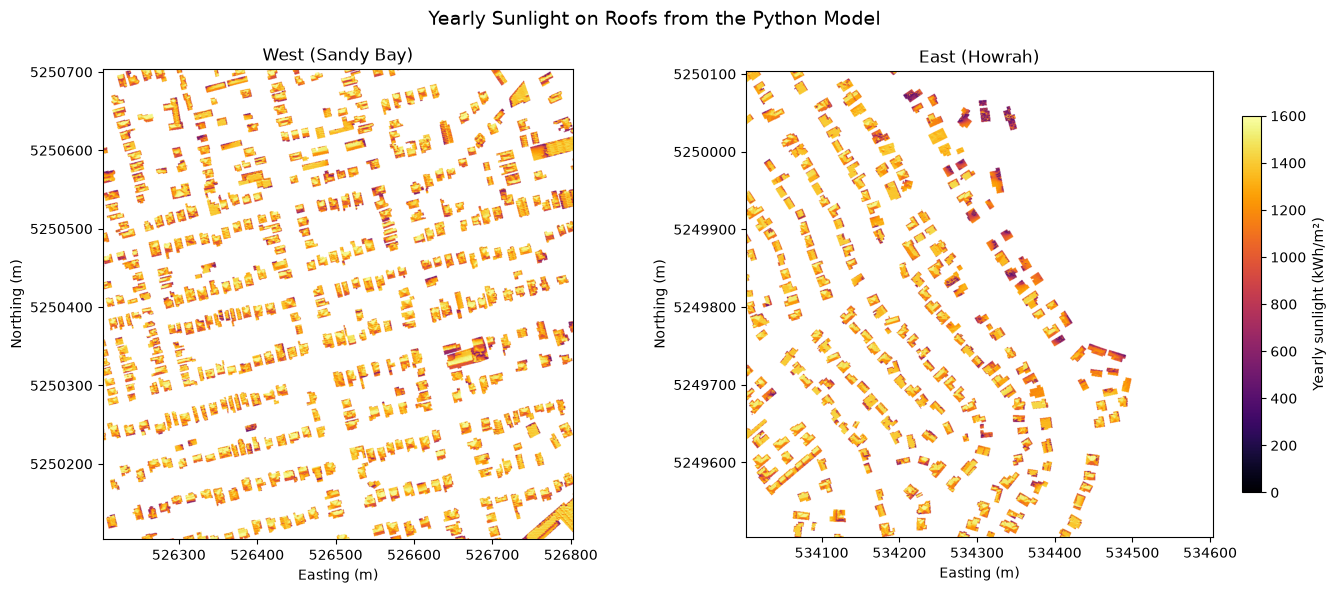

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# West (Sandy Bay)
west_plot = axes[0].imshow(
    west_model_roofs, cmap="inferno", vmin=0, vmax=1600, extent=west_extent
)
axes[0].set_title("West (Sandy Bay)")
axes[0].set_xlabel("Easting (m)")
axes[0].set_ylabel("Northing (m)")
# Show full coordinates and not scientific notation
axes[0].ticklabel_format(style="plain", useOffset=False)

# East (Howrah)
east_plot = axes[1].imshow(
    east_model_roofs, cmap="inferno", vmin=0, vmax=1600, extent=east_extent
)
axes[1].set_title("East (Howrah)")
axes[1].set_xlabel("Easting (m)")
axes[1].set_ylabel("Northing (m)")
axes[1].ticklabel_format(style="plain", useOffset=False)

# One colourbar covers both maps because they share the same scale
fig.colorbar(
    east_plot, ax=axes[1], label="Yearly sunlight (kWh/m²)", shrink=0.8
)

fig.suptitle("Yearly Sunlight on Roofs from the Python Model", fontsize=14)
plt.tight_layout()
fig.savefig("Images/yearly_sunlight_roofs.png", dpi=200, bbox_inches="tight")
plt.show()

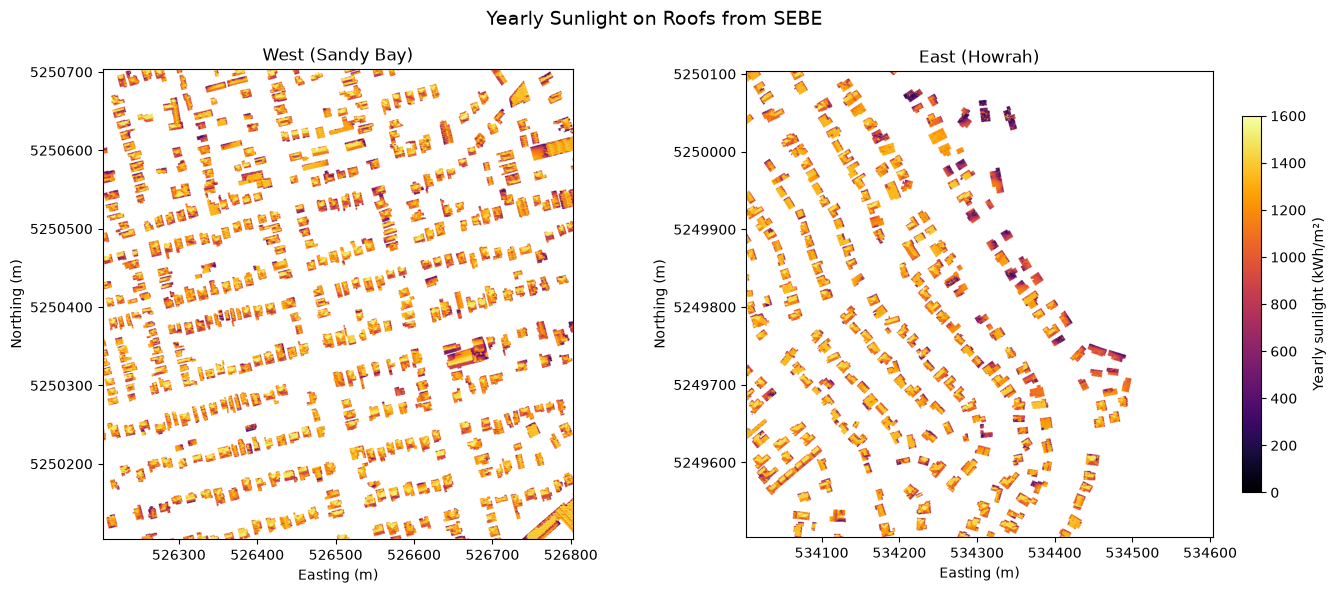

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# West (Sandy Bay)
west_plot = axes[0].imshow(
    west_sebe_roofs, cmap="inferno", vmin=0, vmax=1600, extent=west_extent
)
axes[0].set_title("West (Sandy Bay)")
axes[0].set_xlabel("Easting (m)")
axes[0].set_ylabel("Northing (m)")
# Show full coordinates and not scientific notation
axes[0].ticklabel_format(style="plain", useOffset=False)

# East (Howrah)
east_plot = axes[1].imshow(
    east_sebe_roofs, cmap="inferno", vmin=0, vmax=1600, extent=east_extent
)
axes[1].set_title("East (Howrah)")
axes[1].set_xlabel("Easting (m)")
axes[1].set_ylabel("Northing (m)")
axes[1].ticklabel_format(style="plain", useOffset=False)

# One colourbar covers both maps because they share the same scale
fig.colorbar(
    east_plot, ax=axes[1], label="Yearly sunlight (kWh/m²)", shrink=0.8
)

fig.suptitle("Yearly Sunlight on Roofs from SEBE", fontsize=14)
plt.tight_layout()
fig.savefig(
    "Images/yearly_sunlight_roofs_sebe.png", dpi=200, bbox_inches="tight"
)
plt.show()

## 4. Suitability criteria

A roof pixel is suitable for a solar panel if it passes all three rules:

| Rule | Limit | Source |
|---|---|---|
| On a building | Inside a building footprint | [LIST building footprints](https://listdata.thelist.tas.gov.au/opendata/) |
| Not a wall | Slope of 65° or less | [UMEP SEBE tutorial](https://umep-docs.readthedocs.io/projects/tutorial/en/latest/Tutorials/SEBE.html) |
| Enough sun | At least 80% of the yearly sunlight on unshaded flat ground | [Roberts, Copper and Bruce (2018)](https://energyconsumersaustralia.com.au/sites/default/files/2025-05/apsrc-paper-rooftop-solar-potential-2018.pdf) |

The SEBE tutorial treats pixels steeper than 65° as walls. Roberts, Copper and Bruce select roof areas that receive 80% of the sunlight on an unshaded horizontal surface. For Hobart that is 0.8 × 1,424 = 1,139 kWh/m².

There is no separate rule for aspect or shading. South-facing and shaded pixels get less sun, so they fail the sunlight rule. The criteria are applied to the Python model results.

Each pixel is 0.5 m × 0.5 m, so the number of pixels is multiplied by 0.25 m² to get an area.

In [11]:
# Steepest slope that still counts as roof and not wall, in degrees
max_slope = 65

# Yearly sunlight on unshaded flat ground, which is the yearly GHI
# from the weather file (notebook 01)
flat_ground_sunlight = 1424

# A pixel needs at least 80% of that to count as getting enough sun
min_sunlight = 0.8 * flat_ground_sunlight

print("Minimum yearly sunlight:", round(min_sunlight), "kWh/m2")

Minimum yearly sunlight: 1139 kWh/m2


In [12]:
# A pixel is suitable if it is on a roof, is not a wall and gets
# enough sun. The & means all three have to be true

# West (Sandy Bay)
west_suitable = (
    west_roofs & (west_slope <= max_slope) & (west_model >= min_sunlight)
)

# East (Howrah)
east_suitable = (
    east_roofs & (east_slope <= max_slope) & (east_model >= min_sunlight)
)

In [13]:
# Each pixel is 0.5 m x 0.5 m, so it covers 0.25 m2
pixel_area = 0.25

# Count the pixels and turn the count into an area
west_roof_area = west_roofs.sum() * pixel_area
west_suitable_area = west_suitable.sum() * pixel_area
east_roof_area = east_roofs.sum() * pixel_area
east_suitable_area = east_suitable.sum() * pixel_area

print("West roof area:", round(west_roof_area), "m2")
print("West suitable area:", round(west_suitable_area), "m2")
print("East roof area:", round(east_roof_area), "m2")
print("East suitable area:", round(east_suitable_area), "m2")

West roof area: 76412 m2
West suitable area: 53279 m2
East roof area: 45217 m2
East suitable area: 30504 m2


## 5. Map of suitable roof area

Suitable roof is shown in orange and the rest of the roof in grey. About 70% of the roof area is suitable in Sandy Bay and 67% in Howrah. The grey parts are mostly south-facing roof faces, roof edges and shaded areas.

Resources:
- [matplotlib: making a colormap from a list of colours (ListedColormap)](https://matplotlib.org/stable/users/explain/colors/colormap-manipulation.html)

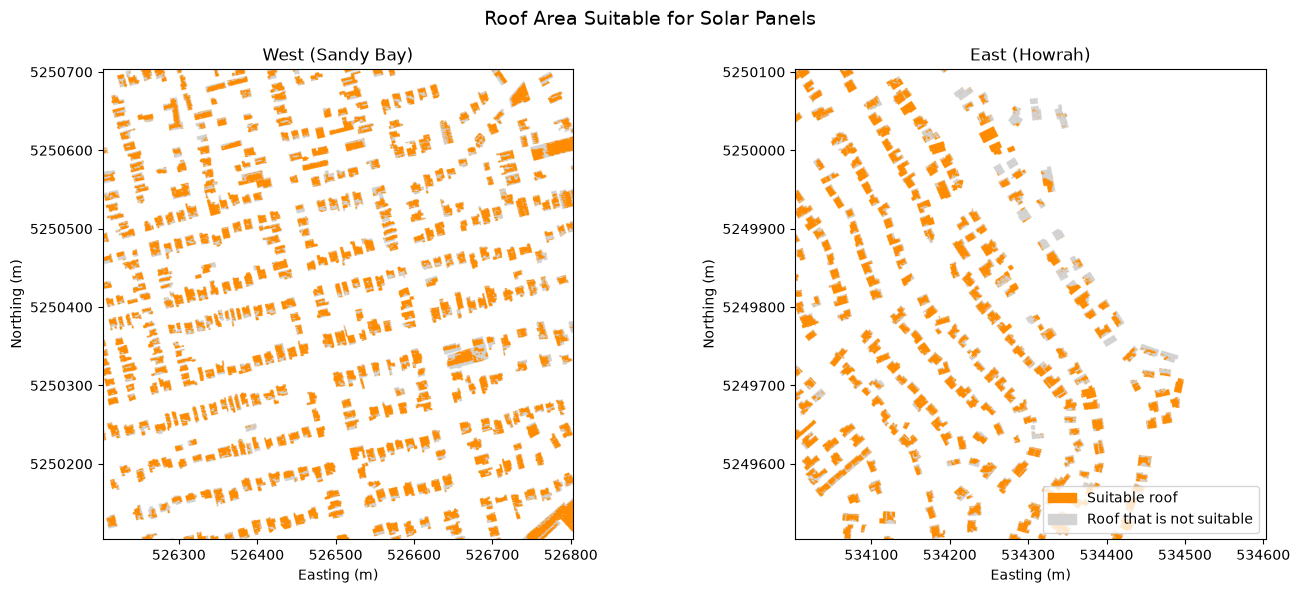

In [14]:
# Give each roof pixel a class: 1 for roof that is not suitable and
# 2 for suitable roof. Pixels that are not roof are left blank
west_classes = np.where(west_roofs, 1.0, np.nan)
west_classes[west_suitable] = 2

east_classes = np.where(east_roofs, 1.0, np.nan)
east_classes[east_suitable] = 2

# Grey for class 1 and orange for class 2
colours = ListedColormap(["lightgrey", "darkorange"])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# West (Sandy Bay)
axes[0].imshow(
    west_classes, cmap=colours, vmin=1, vmax=2, extent=west_extent
)
axes[0].set_title("West (Sandy Bay)")
axes[0].set_xlabel("Easting (m)")
axes[0].set_ylabel("Northing (m)")
# Show full coordinates and not scientific notation
axes[0].ticklabel_format(style="plain", useOffset=False)

# East (Howrah)
axes[1].imshow(
    east_classes, cmap=colours, vmin=1, vmax=2, extent=east_extent
)
axes[1].set_title("East (Howrah)")
axes[1].set_xlabel("Easting (m)")
axes[1].set_ylabel("Northing (m)")
axes[1].ticklabel_format(style="plain", useOffset=False)

# A legend with one box for each class
legend_boxes = [
    Patch(color="darkorange", label="Suitable roof"),
    Patch(color="lightgrey", label="Roof that is not suitable"),
]
axes[1].legend(handles=legend_boxes, loc="lower right")

fig.suptitle("Roof Area Suitable for Solar Panels", fontsize=14)
plt.tight_layout()
fig.savefig("Images/suitable_roof_area.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Save the results

Saving the suitable roof pixels as a raster (1 for suitable, 0 for not), so they can be opened in QGIS.

In [15]:
# Use the same grid details as the model results, but store the values
# as whole numbers
west_profile.update(dtype="uint8", nodata=None)
east_profile.update(dtype="uint8", nodata=None)

# West (Sandy Bay)
# Create the file, write the values into band 1, then close it
west_path = outpath / "West_suitable.tif"
west_output = rasterio.open(west_path, "w", **west_profile)
west_output.write(west_suitable.astype("uint8"), 1)
west_output.close()

# East (Howrah)
east_path = outpath / "East_suitable.tif"
east_output = rasterio.open(east_path, "w", **east_profile)
east_output.write(east_suitable.astype("uint8"), 1)
east_output.close()

print("Suitable roof files saved")

Suitable roof files saved


## Summary

Both models were limited to rooftops and saved as `West_python_roofs.tif`, `West_sebe_roofs.tif`, `East_python_roofs.tif` and `East_sebe_roofs.tif`, which are compared in QGIS. About two thirds of the roof area in both test areas passes the suitability criteria, and these pixels are saved as `West_suitable.tif` and `East_suitable.tif`.

## 7. Maps for comparing the two models

Each model is saved as its own map at the same size, extent and colour scale, so they line up exactly and can be shown in tabs on the website. We also map the difference between the two models (our model minus SEBE) on every roof pixel. Red means our model is higher and blue means SEBE is higher. Because the colour scale is centred on zero, white means the two models agree.

In [16]:
# Our model minus SEBE on every roof pixel, in kWh/m2
west_difference = west_model_roofs - west_sebe_roofs
east_difference = east_model_roofs - east_sebe_roofs

# Average difference on roofs, so we know which model is higher overall
print("West average difference:", round(np.nanmean(west_difference)), "kWh/m2")
print("East average difference:", round(np.nanmean(east_difference)), "kWh/m2")

West average difference: 100 kWh/m2
East average difference: 105 kWh/m2


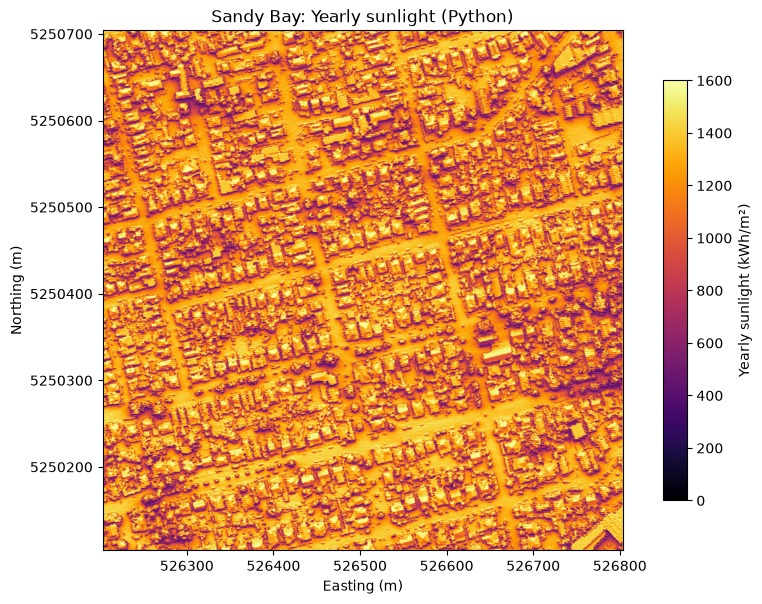

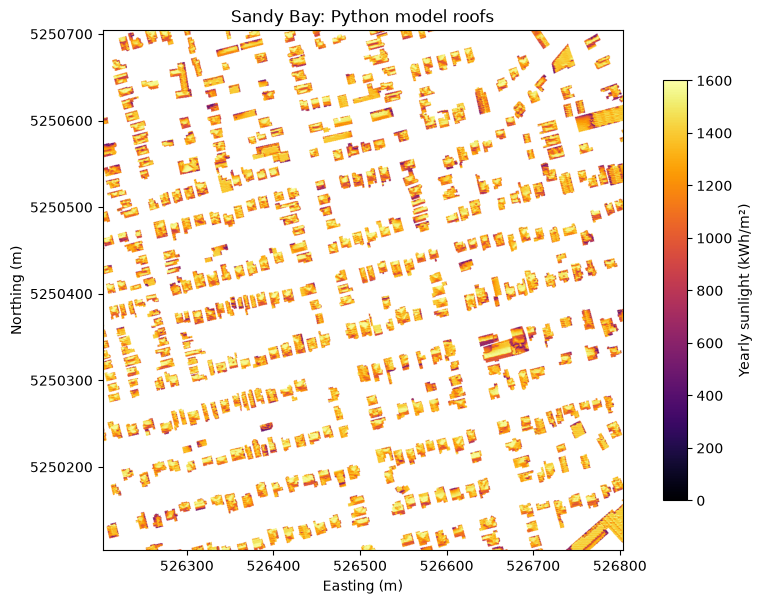

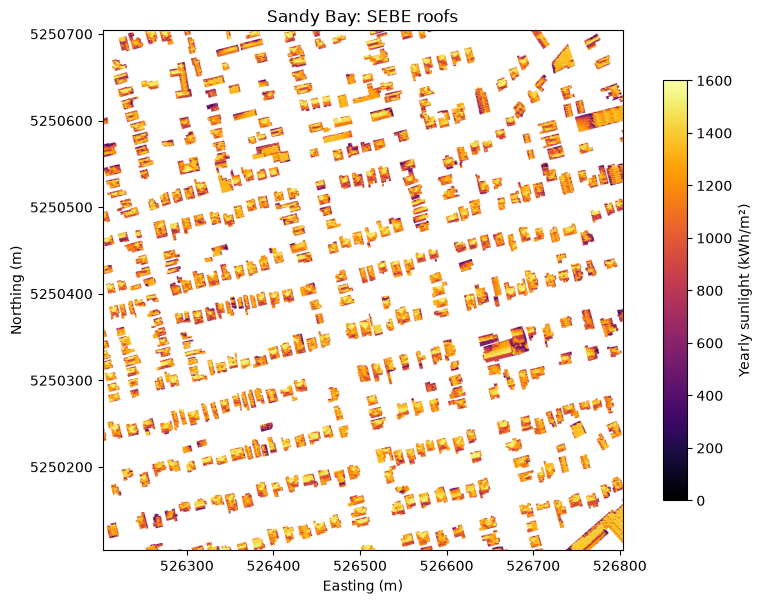

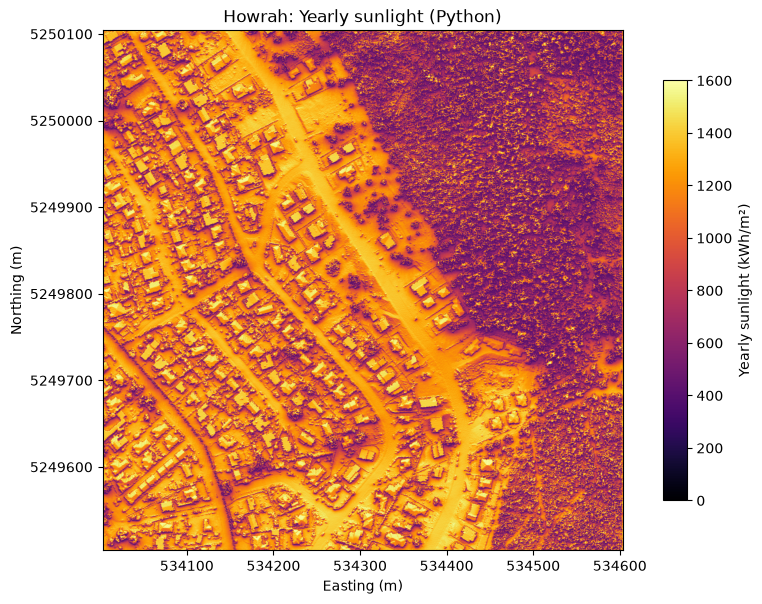

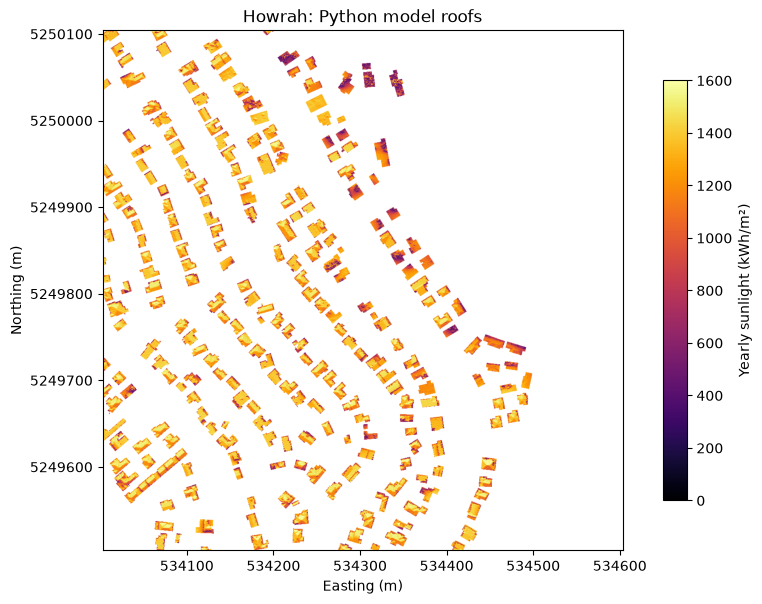

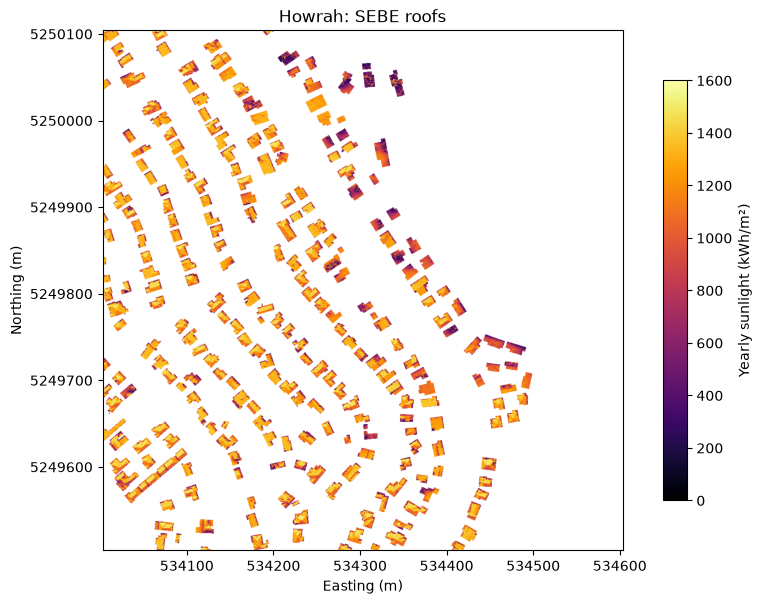

In [17]:
# Yearly sunlight maps, all on the same 0 to 1600 scale
sunlight_maps = [
    (west_model, west_extent, "Sandy Bay: Yearly sunlight (Python)",
     "west_yearly.png"),
    (west_model_roofs, west_extent, "Sandy Bay: Python model roofs",
     "west_python.png"),
    (west_sebe_roofs, west_extent, "Sandy Bay: SEBE roofs",
     "west_sebe.png"),
    (east_model, east_extent, "Howrah: Yearly sunlight (Python)",
     "east_yearly.png"),
    (east_model_roofs, east_extent, "Howrah: Python model roofs",
     "east_python.png"),
    (east_sebe_roofs, east_extent, "Howrah: SEBE roofs",
     "east_sebe.png"),
]

for values, extent, title, filename in sunlight_maps:
    fig = plt.figure(figsize=(8, 7))

    # Fixed positions for the map and the colourbar, so every map sits in
    # exactly the same place and they line up when switching tabs
    ax = fig.add_axes([0.12, 0.1, 0.65, 0.8])
    bar_ax = fig.add_axes([0.82, 0.2, 0.03, 0.6])

    plot = ax.imshow(
        values, cmap="inferno", vmin=0, vmax=1600, extent=extent
    )
    ax.set_title(title)
    ax.set_xlabel("Easting (m)")
    ax.set_ylabel("Northing (m)")
    # Show full coordinates and not scientific notation
    ax.ticklabel_format(style="plain", useOffset=False)

    fig.colorbar(plot, cax=bar_ax, label="Yearly sunlight (kWh/m²)")

    fig.savefig("Images/" + filename, dpi=200)
    plt.show()

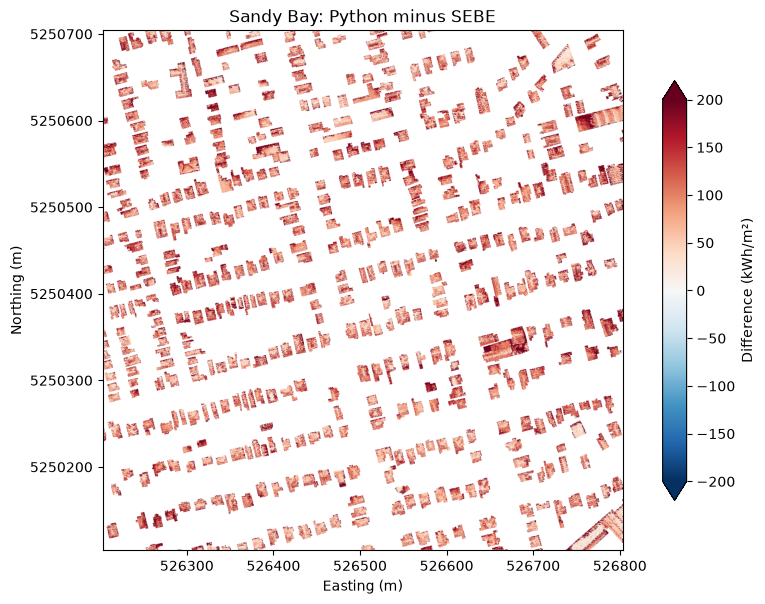

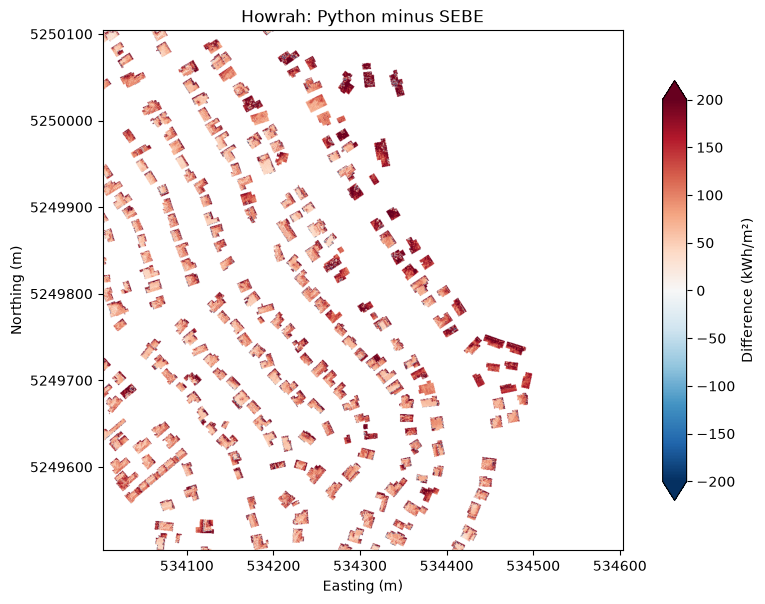

In [18]:
# Difference maps. Red is where our model is higher and blue is where
# SEBE is higher. The scale is kept small so the differences stand out,
# and anything outside it is shown in the darkest colour
scale = 200

difference_maps = [
    (west_difference, west_extent, "Sandy Bay: Python minus SEBE",
     "west_difference.png"),
    (east_difference, east_extent, "Howrah: Python minus SEBE",
     "east_difference.png"),
]

for values, extent, title, filename in difference_maps:
    fig = plt.figure(figsize=(8, 7))
    ax = fig.add_axes([0.12, 0.1, 0.65, 0.8])
    bar_ax = fig.add_axes([0.82, 0.2, 0.03, 0.6])

    plot = ax.imshow(
        values, cmap="RdBu_r", vmin=-scale, vmax=scale, extent=extent
    )
    ax.set_title(title)
    ax.set_xlabel("Easting (m)")
    ax.set_ylabel("Northing (m)")
    ax.ticklabel_format(style="plain", useOffset=False)

    # The arrows on the colourbar show values go past the ends of the scale
    fig.colorbar(
        plot, cax=bar_ax, label="Difference (kWh/m²)", extend="both"
    )

    fig.savefig("Images/" + filename, dpi=200)
    plt.show()

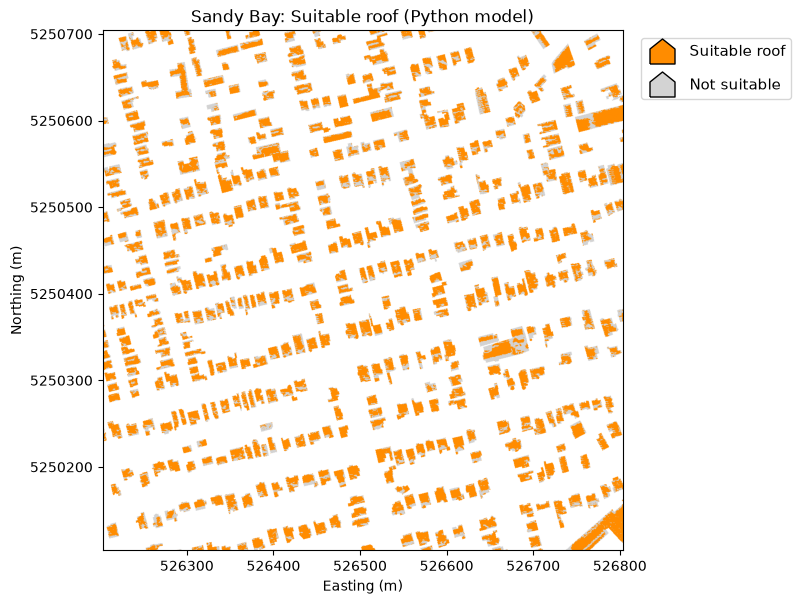

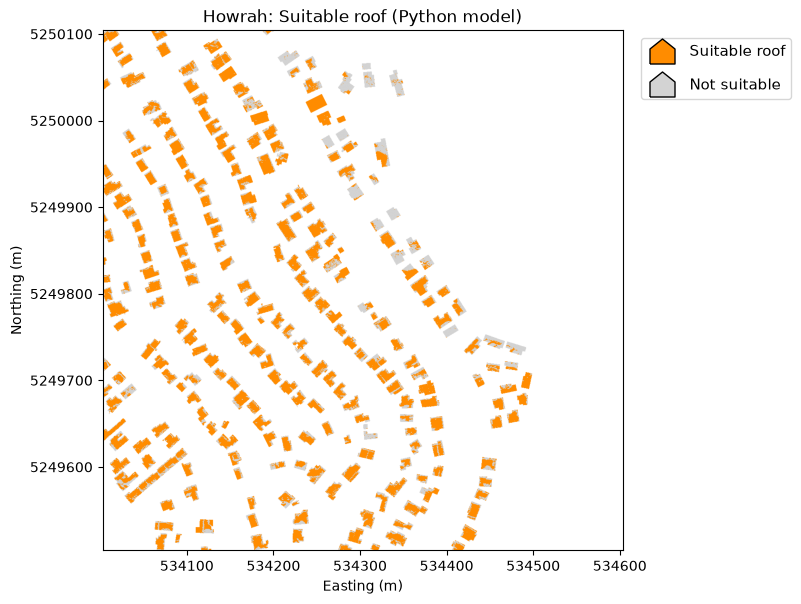

In [19]:
from matplotlib.lines import Line2D

# Suitable roof from the Python model. Orange is suitable and grey is
# roof that is not suitable. Everything that isn't roof is left blank
colours = ListedColormap(["lightgrey", "darkorange"])

suitable_maps = [
    (west_classes, west_extent,
     "Sandy Bay: Suitable roof (Python model)", "west_suitable.png"),
    (east_classes, east_extent,
     "Howrah: Suitable roof (Python model)", "east_suitable.png"),
]

# Corner points of a simple house shape (walls and a pointed roof),
# used as the legend symbol
house = [(-1, -1), (1, -1), (1, 0.2), (0, 1), (-1, 0.2), (-1, -1)]

legend_boxes = [
    Line2D(
        [0], [0], marker=house, color="none", markersize=18,
        markerfacecolor="darkorange", markeredgecolor="black",
        label="Suitable roof",
    ),
    Line2D(
        [0], [0], marker=house, color="none", markersize=18,
        markerfacecolor="lightgrey", markeredgecolor="black",
        label="Not suitable",
    ),
]

for values, extent, title, filename in suitable_maps:
    fig = plt.figure(figsize=(8, 7))

    # Same map position as the other maps. There's no colourbar here, so
    # the legend goes in the space where the colourbar would be
    ax = fig.add_axes([0.12, 0.1, 0.65, 0.8])

    ax.imshow(values, cmap=colours, vmin=1, vmax=2, extent=extent)
    ax.set_title(title)
    ax.set_xlabel("Easting (m)")
    ax.set_ylabel("Northing (m)")
    ax.ticklabel_format(style="plain", useOffset=False)

    ax.legend(
        handles=legend_boxes, loc="upper left", bbox_to_anchor=(1.02, 1),
        fontsize=11, labelspacing=1.2,
    )

    fig.savefig("Images/" + filename, dpi=200)
    plt.show()

In [20]:
# Side by side numbers for the two areas, roof cells only
for name, model, sebe, classes in [
    ("Sandy Bay", west_model_roofs, west_sebe_roofs, west_classes),
    ("Howrah", east_model_roofs, east_sebe_roofs, east_classes),
]:
    # Average yearly sunlight on roofs for each model
    model_mean = np.nanmean(model)
    sebe_mean = np.nanmean(sebe)

    # Average difference, in kWh/m² and as a percent of SEBE
    difference = model_mean - sebe_mean
    percent = difference / sebe_mean * 100

    # Roof area and suitable area (each cell is 0.25 m²)
    roof_area = np.sum(classes > 0) * 0.25
    suitable_area = np.sum(classes == 2) * 0.25

    print(name)
    print("  Python mean:", round(model_mean), "kWh/m²")
    print("  SEBE mean:", round(sebe_mean), "kWh/m²")
    print("  Difference:", round(difference), "kWh/m² (", round(percent, 1), "% )")
    print("  Roof area:", round(roof_area), "m²")
    print("  Suitable area:", round(suitable_area), "m²",
          "(", round(suitable_area / roof_area * 100), "% )")

Sandy Bay
  Python mean: 1252 kWh/m²
  SEBE mean: 1151 kWh/m²
  Difference: 100 kWh/m² ( 8.7 % )
  Roof area: 76412 m²
  Suitable area: 53279 m² ( 70 % )
Howrah
  Python mean: 1219 kWh/m²
  SEBE mean: 1114 kWh/m²
  Difference: 105 kWh/m² ( 9.5 % )
  Roof area: 45217 m²
  Suitable area: 30504 m² ( 67 % )
